# Joint motion and beta inference from RFID

Each parameter particle carries a motion particle filter for x, y, vx, vy. RFID measurements update motion estimates and parameter weights together. No observed acceleration or true motion state is supplied to inference.

Compare **PF ignoring confounding** against **instrument-aware PF** on identical recorded RSSI/bearing readings and observed u,z. The latter learns the residual relationship, rather than receiving hidden confounder values. It still relies on valid instrument information; it is not identification of confounding without instruments.

Both assume one unknown **constant beta per run**, matching this generator's chosen formulation. That does not fix beta to the true value: its posterior changes with observations. The comparison does not establish performance under a time-varying beta.

Motion/noise parameters are unknown with generic fixed priors. RFID sensor calibration is an explicit known measurement-model assumption. Gaussian motion likelihoods remain approximations to the non-Gaussian generator. No claim of superiority should be made from this single realization.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from copy import deepcopy
from html import escape
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "controls" / "JointParticleFilterEstimator.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from controls import (JointParticleFilterEstimator, JointFilterContext, ParameterPrior,
                      RFIDSensor, RFIDConfig, RFIDMeasurement, ReaderState)
from controls.scenarios.instruments import generateInstruments
from controls.scenarios.instrumented import generateTrajectory

No event loop hook running.


## Generate sensor observations; keep evaluation truth separate

The reader stays at a predefined origin. Sensor noise is deliberately modest for this first hidden-state experiment: 0.5 dB RSSI and 0.02 rad bearing, plus 5% random dropout and a 100 m range. These are synthetic calibration settings, not measured hardware performance.

A second replay withholds all readings from 5 to 7 seconds, without changing the path, inputs, instruments, or other readings. Invalid reads are treated as uninformative. The input on interval i is supplied with reading i+1, aligning the generator's Euler update.

In [2]:
DURATION, DT = 12.0, 0.2
TRUE_BETA = 0.5  # Simulator and offline evaluation only.
INSTRUMENT_SEED, TRAJECTORY_SEED, DISTRIBUTION_SEED, SENSOR_SEED = 42, 123, 7, 456
SENSOR_CONFIG = RFIDConfig(rssiStdDev=0.5, bearingStdDev=0.02, maxRange=100, updateRate=1/DT)
reader = ReaderState()
instruments = generateInstruments(duration=DURATION, dt=DT, seed=INSTRUMENT_SEED)
generated = generateTrajectory(instruments, beta=TRUE_BETA, seed=TRAJECTORY_SEED, distributionSeed=DISTRIBUTION_SEED)
sensor = RFIDSensor(SENSOR_CONFIG, seed=SENSOR_SEED)
readings = [sensor.measure(state, reader) for state in generated.scenario.states]
records = []
for i, measurement in enumerate(readings):
    context = JointFilterContext(deepcopy(reader), generated.inputs[i-1] if i else None,
                                 (instruments[i-1].z_x, instruments[i-1].z_y) if i else None)
    records.append((i*DT, deepcopy(measurement), context))

evaluation_states = np.array([[s.position.x, s.position.y, s.xdot, s.ydot] for s in generated.scenario.states])
OUTAGE = (5.0, 7.0)
outage_records = deepcopy(records)
for time, measurement, context in outage_records:
    if OUTAGE[0] <= time < OUTAGE[1]:
        measurement.isValid = False
observation_cases = {"Original RFID readings": records, "RFID outage": outage_records}
del generated  # Inference receives only observation records, never this object.
print(f"{len(records)} reading times, {sum(m.isValid for _, m, _ in records)} valid original reads")

61 reading times, 56 valid original reads


## Joint inference

The boundary below accepts observations, known sensor calibration, dt and generic inference settings. It never accepts evaluation states, true beta, hidden mixture parameters, or true accelerations.

Parameter resampling uses particle marginal Metropolis moves: proposed static parameters replay only readings received so far through their own bootstrap state filters. This follows the nested-filter idea in [SMC²](https://arxiv.org/abs/1101.1528). A finite number of particles can still yield noisy likelihoods and slow parameter mixing; acceptance rates are shown below. It is costlier than the earlier observed-acceleration benchmark.

`lastPrediction` is formed **before** the reading at that timestep is consumed. Its error therefore tests prediction rather than fitting the same reading.

In [3]:
PARAMETER_COUNT, STATE_PARTICLE_COUNT, INFERENCE_SEED = 256, 128, 789
INFERENCE_PRIOR = ParameterPrior()  # Fixed independently of generator truth.

def run_joint(records, *, sensor_config, dt, mode, parameter_count, state_particle_count, prior, seed):
    estimator = JointParticleFilterEstimator(
        sensor_config, mode=mode, parameterCount=parameter_count, stateParticleCount=state_particle_count,
        prior=prior, seed=seed,
    )
    states, forecasts, beta, lower, upper, ess, acceptance = [], [], [], [], [], [], []
    for i, (time, measurement, context) in enumerate(records):
        state = estimator.update(measurement, context, dt, time=time, predict=i>0)
        states.append([state.position.x, state.position.y, state.xdot, state.ydot] if state else [np.nan]*4)
        forecast = estimator.lastPrediction
        forecasts.append([forecast.mean.position.x, forecast.mean.position.y, forecast.mean.xdot, forecast.mean.ydot]
                         if forecast else [np.nan]*4)
        h = estimator.history[-1] if state else None
        beta.append(h.beta if h else np.nan)
        lower.append(h.lower95 if h else np.nan)
        upper.append(h.upper95 if h else np.nan)
        ess.append(h.parameterESS if h else np.nan)
        acceptance.append(h.moveAcceptanceRate if h and h.moveAcceptanceRate is not None else np.nan)
    return dict(estimator=estimator, states=np.array(states), forecasts=np.array(forecasts), beta=np.array(beta),
                lower=np.array(lower), upper=np.array(upper), ess=np.array(ess), acceptance=np.array(acceptance))

METHODS = {"PF ignoring confounding": "independent", "Instrument-aware PF": "shared"}
runs = {}
for case_name, observation_records in observation_cases.items():
    runs[case_name] = {}
    for name, mode in METHODS.items():
        runs[case_name][name] = run_joint(
            observation_records, sensor_config=SENSOR_CONFIG, dt=DT, mode=mode, parameter_count=PARAMETER_COUNT,
            state_particle_count=STATE_PARTICLE_COUNT, prior=INFERENCE_PRIOR, seed=INFERENCE_SEED,
        )
    print(f"Completed: {case_name}")

Completed: Original RFID readings
Completed: RFID outage


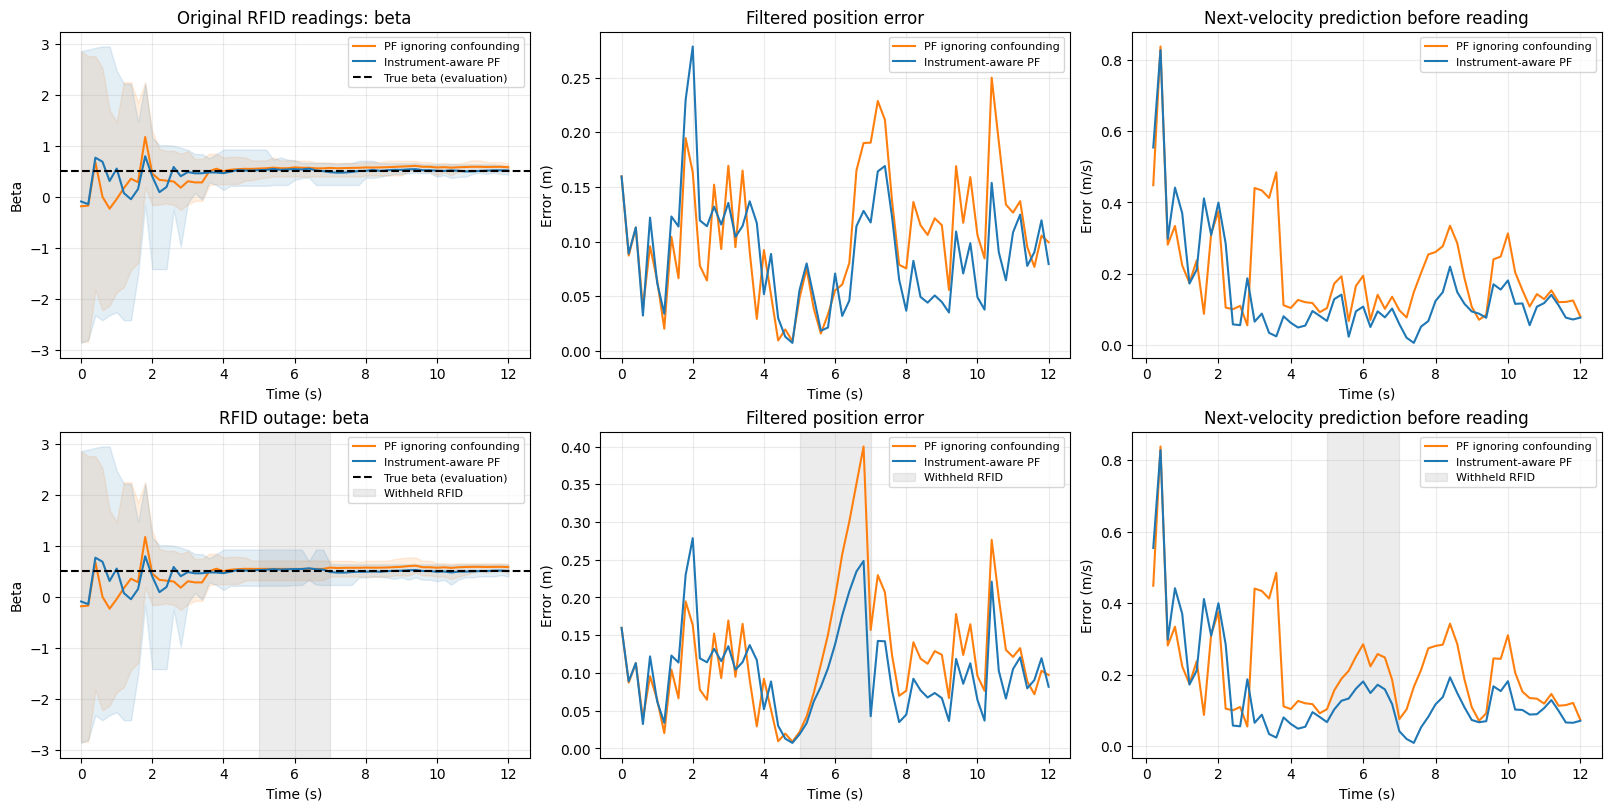

Case,Method,Final beta,Position RMSE (m),Velocity RMSE (m/s),Forecast position RMSE (m),Forecast velocity RMSE (m/s),Mean move acceptance
Original RFID readings,PF ignoring confounding,0.5827,0.119,0.232,0.145,0.242,8.2%
Original RFID readings,Instrument-aware PF,0.5208,0.104,0.204,0.128,0.205,8.5%
RFID outage,PF ignoring confounding,0.5862,0.146,0.243,0.176,0.253,8.3%
RFID outage,Instrument-aware PF,0.5099,0.118,0.208,0.142,0.207,8.9%


In [4]:
# Ground truth enters only here, after inference, for scoring and plotting.
time = np.array([t for t, _, _ in records])
colors = {"PF ignoring confounding": "tab:orange", "Instrument-aware PF": "tab:blue"}
fig, axes = plt.subplots(len(runs), 3, figsize=(16, 8), squeeze=False, constrained_layout=True)
rows = []
for row, (case_name, case_runs) in enumerate(runs.items()):
    for name, run in case_runs.items():
        position_error = np.linalg.norm(run["states"][:, :2]-evaluation_states[:, :2], axis=1)
        velocity_error = np.linalg.norm(run["states"][:, 2:]-evaluation_states[:, 2:], axis=1)
        forecast_position_error = np.linalg.norm(run["forecasts"][:, :2]-evaluation_states[:, :2], axis=1)
        forecast_velocity_error = np.linalg.norm(run["forecasts"][:, 2:]-evaluation_states[:, 2:], axis=1)
        axes[row, 0].plot(time, run["beta"], color=colors[name], label=name)
        axes[row, 0].fill_between(time, run["lower"], run["upper"], color=colors[name], alpha=0.12)
        axes[row, 1].plot(time, position_error, color=colors[name], label=name)
        axes[row, 2].plot(time, forecast_velocity_error, color=colors[name], label=name)
        acceptance = run["acceptance"][np.isfinite(run["acceptance"])]
        rows.append([case_name, name, f"{run['beta'][-1]:.4f}",
                     f"{np.sqrt(np.nanmean(position_error**2)):.3f}",
                     f"{np.sqrt(np.nanmean(velocity_error**2)):.3f}",
                     f"{np.sqrt(np.nanmean(forecast_position_error**2)):.3f}",
                     f"{np.sqrt(np.nanmean(forecast_velocity_error**2)):.3f}",
                     f"{np.mean(acceptance):.1%}" if len(acceptance) else "No moves"])
    axes[row, 0].axhline(TRUE_BETA, color="black", linestyle="--", label="True beta (evaluation)")
    axes[row, 0].set(title=f"{case_name}: beta", ylabel="Beta")
    axes[row, 1].set(title="Filtered position error", ylabel="Error (m)")
    axes[row, 2].set(title="Next-velocity prediction before reading", ylabel="Error (m/s)")
    for ax in axes[row]:
        if case_name == "RFID outage":
            ax.axvspan(*OUTAGE, color="gray", alpha=0.15, label="Withheld RFID")
        ax.set_xlabel("Time (s)")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
plt.show()
headers = ["Case", "Method", "Final beta", "Position RMSE (m)", "Velocity RMSE (m/s)",
           "Forecast position RMSE (m)", "Forecast velocity RMSE (m/s)", "Mean move acceptance"]
html = "<table><tr>" + "".join(f"<th>{escape(h)}</th>" for h in headers) + "</tr>"
html += "".join("<tr>" + "".join(f"<td>{escape(v)}</td>" for v in row) + "</tr>" for row in rows)
display(HTML(html + "</table>"))

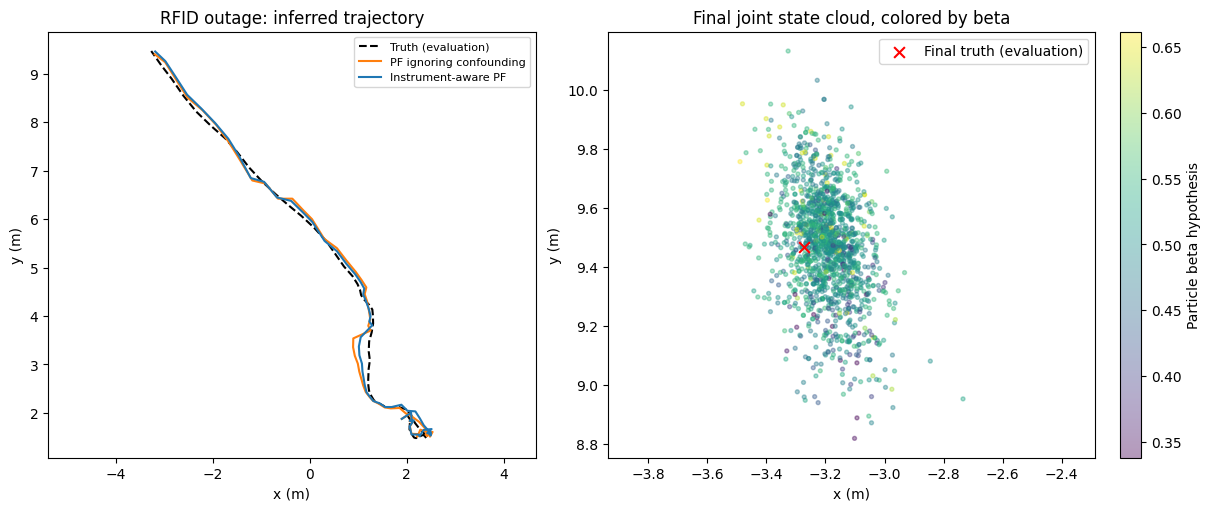

In [5]:
DISPLAY_CASE = "RFID outage"
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].plot(evaluation_states[:, 0], evaluation_states[:, 1], color="black", linestyle="--", label="Truth (evaluation)")
for name, run in runs[DISPLAY_CASE].items():
    axes[0].plot(run["states"][:, 0], run["states"][:, 1], color=colors[name], label=name)
axes[0].set(title=f"{DISPLAY_CASE}: inferred trajectory", xlabel="x (m)", ylabel="y (m)")
axes[0].set_aspect("equal", adjustable="datalim")
axes[0].legend(fontsize=8)

# Draw the displayed cloud from the JOINT posterior weights, using an independent plotting RNG.
filter_ = runs[DISPLAY_CASE]["Instrument-aware PF"]["estimator"]
cloud = filter_.stateParticles.reshape(-1, 4)
weights = (filter_.parameterWeights[:, None]*filter_.stateWeights).ravel()
betas = np.repeat(filter_.parameterParticles[:, 0], STATE_PARTICLE_COUNT)
indices = np.random.default_rng(2026).choice(len(cloud), size=1500, p=weights)
points = axes[1].scatter(cloud[indices, 0], cloud[indices, 1], c=betas[indices], s=8, alpha=0.4, cmap="viridis")
axes[1].scatter(*evaluation_states[-1, :2], color="red", marker="x", s=60, label="Final truth (evaluation)")
axes[1].set(title="Final joint state cloud, colored by beta", xlabel="x (m)", ylabel="y (m)")
axes[1].set_aspect("equal", adjustable="datalim")
axes[1].legend()
fig.colorbar(points, ax=axes[1], label="Particle beta hypothesis")
plt.show()

## What this experiment can show

Instrument information can help separate input response beta from residual correlation, which can also change predicted velocity and uncertainty when readings are absent. Better beta does not guarantee smaller instantaneous state error: frequent accurate readings can dominate the motion model, and finite particle approximations can be noisy.

The instrument-aware model uses instruments through a learned control-function relationship. It is not a PF discovering causal effects without identifying information. There is no separate IV line here: extracting accelerations from estimated hidden states and plugging them into IV would require checking the resulting moment conditions.

Both models assume constant beta, known RFID calibration, observed u/z, and a Gaussian working motion law. First localization is an empirical prior drawn from the first valid reading, with a generic zero-centered velocity prior, not the true initial state. The first reading is then not scored twice. Missed detections provide no geometric information in this prototype.

The nested particle implementation uses fixed inner/outer particle counts. Low Metropolis acceptance indicates noisy likelihoods or poor mixing; increase particle counts and repeat seeds before interpreting precise beta posteriors. Replays retain observation history and can be expensive on long trajectories. This notebook replays a fixed reader/sensor record, not the existing pursuit Simulation interface.